# Module unifié : liens + QR codes

Un seul modèle pour tous les liens : ceux collés par l'utilisateur et ceux lus dans les QR codes.
Tous les liens sont normalisés (sans http://, https:// ni www.) pour avoir la même forme.

## Étape U.1 : Préparation et inventaire des données
On connecte le Drive et on regarde quels fichiers de données on a déjà sauvegardés dans les modules précédents.

In [10]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA = '/content/drive/MyDrive/QR-Shield/data'
MODELS = '/content/drive/MyDrive/QR-Shield/models'

for dossier in [DATA, MODELS]:
    print("\n==", dossier)
    for racine, _, fichiers in os.walk(dossier):
        for f in sorted(fichiers):
            chemin = os.path.join(racine, f)
            print(f"{os.path.relpath(chemin, dossier):60s} {os.path.getsize(chemin)/1e6:8.1f} Mo")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

== /content/drive/MyDrive/QR-Shield/data
unifie.csv                                                       10.7 Mo
links/test.csv                                                    2.4 Mo
links/test_clean.csv                                              2.4 Mo
links/train.csv                                                   7.6 Mo
links/train_clean.csv                                             7.5 Mo
qr/qr_codes_29.pickle                                            95.1 Mo
qr/qr_codes_29_labels.pickle                                      0.0 Mo
qr/qr_liens.csv                                                   0.6 Mo
fichiers/X_challenge.dat                                          8.5 Mo
fichiers/X_test.dat                                             308.3 Mo
fichiers/X_train.dat                                           1027.7 Mo
fichiers/train_garder.npy 

## Étape U.2 : Les deux sources de liens
On charge les liens PhreshPhish (entraînement et test) et les liens lus dans les QR codes, et on regarde leurs colonnes, leur taille et l'équilibre des classes.

In [11]:
import pandas as pd

train_p = pd.read_csv(f"{DATA}/links/train_clean.csv")
test_p  = pd.read_csv(f"{DATA}/links/test_clean.csv")
qr      = pd.read_csv(f"{DATA}/qr/qr_liens.csv")

for nom, df in [("PhreshPhish train", train_p), ("PhreshPhish test", test_p), ("QR codes", qr)]:
    print(f"\n===== {nom} : {df.shape[0]} lignes")
    print("Colonnes :", list(df.columns))
    print(df.head(3).to_string())
    col_label = [c for c in df.columns if "label" in c.lower()]
    if col_label:
        print("Classes :", df[col_label[0]].value_counts().to_dict())


===== PhreshPhish train : 99154 lignes
Colonnes : ['url', 'label', 'date']
                                                                                       url   label        date
0  https://accvrtf-mnages019.tivinalili.com.br/?vrazil=&visitorId=68896ecaaa9130616423953e   phish  2025-07-30
1      https://bellagio.mgmresorts.com/en/entertainment/conservatory-botanical-garden.html  benign  2025-08-21
2                                                     https://informed.deliverywup.top/us/   phish  2025-01-09
Classes : {'benign': 54738, 'phish': 44416}

===== PhreshPhish test : 29711 lignes
Colonnes : ['url', 'label', 'date']
                                                                                                    url   label        date
0                                                   https://www.triplux.mydt.in/canva-pro-subscription/   phish  2025-10-17
1  http://www.advertiser360review.info/l0/https:%2f%2fgamingwallpaper.s3.amazonaws.com%2fc8fd0ead-.html   phish  

## Étape U.3 : Normalisation et fusion
Tous les liens prennent la même forme : on enlève http://, https://, www. et le / final, et le nom de domaine est mis en minuscules.
Les labels deviennent 1 (phishing) et 0 (sûr). On garde une colonne "source" pour pouvoir évaluer chaque source séparément.

In [12]:
import re

def normaliser(url):
    """Même forme pour un lien collé et un lien lu dans un QR code."""
    u = str(url).strip()
    u = re.sub(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", "", u)   # enlève http://, https://, ...
    u = re.sub(r"^www\d*\.", "", u, flags=re.I)          # enlève www. (et www2. ...)
    hote, sep, reste = u.partition("/")
    u = hote.lower() + sep + reste                       # domaine en minuscules
    return u.rstrip("/")

# 1. Mettre les deux sources au même format
p = pd.concat([train_p.assign(partie="train"), test_p.assign(partie="test")])
p = pd.DataFrame({"url_brut": p["url"], "label": (p["label"] == "phish").astype(int),
                  "date": pd.to_datetime(p["date"]), "source": "phreshphish", "partie": p["partie"]})
q = pd.DataFrame({"url_brut": qr["url"], "label": qr["label"].astype(int),
                  "date": pd.NaT, "source": "qr", "partie": None})
tous = pd.concat([p, q], ignore_index=True)
tous["url"] = tous["url_brut"].map(normaliser)

# 2. Exemples avant / après
print(tous.groupby("source").sample(3, random_state=1)[["source", "url_brut", "url"]].to_string())

# 3. Bilan
print("\nTotal :", len(tous), "liens")
print(tous.groupby("source")["label"].value_counts().unstack())
print("\nLiens vides après normalisation :", (tous["url"] == "").sum())

             source                                                     url_brut                                                  url
44340   phreshphish         https://www.wikihow.com/Sell-High-End-Used-Furniture             wikihow.com/Sell-High-End-Used-Furniture
84500   phreshphish             https://www.calchamber.com/calchamber-membership                 calchamber.com/calchamber-membership
60800   phreshphish  https://customer.questblue.com/account/managebillingprofile  customer.questblue.com/account/managebillingprofile
130027           qr                              forums.delphiforums.com/apple2/                       forums.delphiforums.com/apple2
137984           qr                                            www.heeg.de/~hmm/                                         heeg.de/~hmm
130404           qr                                web.utk.edu/~tancon/call.html                        web.utk.edu/~tancon/call.html

Total : 138852 liens
label            0      1
source        

## Étape U.4 : Doublons, découpage et vérification des fuites
- Doublons : après normalisation, deux liens identiques ne gardent qu'une ligne (et on retire ceux qui ont deux labels différents).
- Découpage : PhreshPhish par date (le test d'origine est le plus récent ; validation = 20 % les plus récents de l'entraînement). QR codes : par domaine (70/15/15), car il n'y a pas de date.
- Fuite : un même domaine ne doit pas être à la fois dans l'entraînement et dans la validation ou le test.
- Raccourcis : on compare quelques indices simples entre phishing et sûr, pour chaque source.

In [13]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

tous["domaine"] = tous["url"].str.split(r"[/?#]", n=1, regex=True).str[0].str.split(":").str[0]

# 1. Doublons et labels contradictoires
avant = len(tous)
conflits = tous.groupby("url")["label"].nunique()
tous = tous[~tous["url"].isin(conflits[conflits > 1].index)]
tous = tous.sort_values("date").drop_duplicates("url", keep="first")
print(f"Doublons + conflits retirés : {avant - len(tous)}  (conflits : {(conflits > 1).sum()})")

# 2. Découpage
tous["ens"] = None
p = tous["source"] == "phreshphish"
tous.loc[p & (tous["partie"] == "test"), "ens"] = "test"
tr = p & (tous["partie"] == "train")
coupure = tous.loc[tr, "date"].quantile(0.8)
tous.loc[tr & (tous["date"] <= coupure), "ens"] = "train"
tous.loc[tr & (tous["date"] > coupure), "ens"] = "val"

q = tous[tous["source"] == "qr"]
g1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
i_tr, i_reste = next(g1.split(q, groups=q["domaine"]))
reste = q.iloc[i_reste]
g2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
i_val, i_te = next(g2.split(reste, groups=reste["domaine"]))
tous.loc[q.index[i_tr], "ens"] = "train"
tous.loc[reste.index[i_val], "ens"] = "val"
tous.loc[reste.index[i_te], "ens"] = "test"

# 3. Fuite de domaines : on retire de l'entraînement les domaines présents en validation ou en test
dom_eval = set(tous.loc[tous["ens"] != "train", "domaine"])
fuite = (tous["ens"] == "train") & tous["domaine"].isin(dom_eval)
print("Lignes d'entraînement retirées (domaine aussi en val/test) :", int(fuite.sum()))
tous = tous[~fuite]

print("\nTaille des ensembles :")
print(tous.groupby(["ens", "source"])["label"].agg(["count", "mean"]).round(3)
          .rename(columns={"count": "liens", "mean": "part phishing"}))

# 4. Raccourcis possibles : indices simples par source et par classe
ind = pd.DataFrame({
    "source": tous["source"], "label": tous["label"],
    "a '?'": tous["url"].str.contains(r"\?", regex=True),
    "a '/'": tous["url"].str.contains("/"),
    "longueur": tous["url"].str.len(),
    "nb points domaine": tous["domaine"].str.count(r"\."),
})
print("\nIndices moyens (0 = sûr, 1 = phishing) :")
print(ind.groupby(["source", "label"]).mean().round(2))

Doublons + conflits retirés : 1658  (conflits : 1)
Lignes d'entraînement retirées (domaine aussi en val/test) : 22533

Taille des ensembles :
                   liens  part phishing
ens   source                           
test  phreshphish  29675          0.462
      qr            1343          0.484
train phreshphish  57043          0.608
      qr            5895          0.514
val   phreshphish  19440          0.285
      qr            1265          0.481

Indices moyens (0 = sûr, 1 = phishing) :
                   a '?'  a '/'  longueur  nb points domaine
source      label                                           
phreshphish 0       0.00   0.90     48.54               1.37
            1       0.10   0.52     44.16               1.81
qr          0       0.04   1.00     33.15               1.48
            1       0.35   0.92     91.29               2.35


## Étape U.5 : Suppression du raccourci "?"
Dans PhreshPhish, aucun lien sûr n'a de paramètres (0 % contre 10 % pour le phishing) : le modèle apprendrait "? = phishing", ce qui est faux dans la réalité (youtube.com/watch?v=...).
On enlève donc les paramètres (après ? ou #) de tous les liens, puis on retire à nouveau les doublons créés.

In [14]:
# 1. Enlever les paramètres de tous les liens
tous["url"] = tous["url"].str.split(r"[?#]", n=1, regex=True).str[0].str.rstrip("/")

# 2. Nouveaux doublons et conflits (ex. deux liens qui ne différaient que par leurs paramètres)
avant = len(tous)
conflits = tous.groupby("url")["label"].nunique()
tous = tous[~tous["url"].isin(conflits[conflits > 1].index)]
ordre = {"test": 0, "val": 1, "train": 2}            # en cas de doublon entre ensembles, on garde val/test
tous = tous.sort_values("ens", key=lambda s: s.map(ordre)).drop_duplicates("url", keep="first")
print(f"Retirés : {avant - len(tous)}  (conflits : {(conflits > 1).sum()})")

# 3. Nouveau contrôle des indices
ind = pd.DataFrame({
    "source": tous["source"], "label": tous["label"],
    "a '/'": tous["url"].str.contains("/"),
    "longueur": tous["url"].str.len(),
    "nb points domaine": tous["domaine"].str.count(r"\."),
})
print(ind.groupby(["source", "label"]).mean().round(2))
print("\nTaille des ensembles :")
print(tous.groupby(["ens", "source"])["label"].agg(["count", "mean"]).round(3)
          .rename(columns={"count": "liens", "mean": "part phishing"}))

# 4. Sauvegarde du tableau final (pour ne pas tout refaire)
tous[["url", "label", "source", "ens", "domaine", "date"]].to_csv(f"{DATA}/unifie.csv", index=False)
print("\nSauvegardé :", f"{DATA}/unifie.csv")

Retirés : 1122  (conflits : 0)
                   a '/'  longueur  nb points domaine
source      label                                    
phreshphish 0       0.90     48.54               1.37
            1       0.45     37.09               1.81
qr          0       1.00     32.32               1.49
            1       0.90     61.57               2.43

Taille des ensembles :
                   liens  part phishing
ens   source                           
test  phreshphish  29352          0.456
      qr            1231          0.442
train phreshphish  56901          0.607
      qr            5562          0.492
val   phreshphish  19268          0.279
      qr            1225          0.466

Sauvegardé : /content/drive/MyDrive/QR-Shield/data/unifie.csv


## Étape U.6 : Features, baseline et XGBoost
Chaque lien normalisé devient : 12 features simples + TF-IDF de caractères (morceaux de 3 à 5 lettres, 20 000 max).
Le TF-IDF est appris seulement sur l'entraînement (split-then-fit).
Baseline : régression logistique. Modèle principal : XGBoost.
Comparaison sur la validation, au seuil 0,5, pour chaque source séparément.

In [15]:
import math, time
from collections import Counter
from urllib.parse import urlparse
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MaxAbsScaler

MOTS_SUSPECTS = ["login", "verify", "account", "update", "secure", "bank",
                 "signin", "confirm", "password", "wallet", "support", "billing"]

def entropie(t):
    if not t: return 0.0
    return -sum((n/len(t)) * math.log2(n/len(t)) for n in Counter(t).values())

def features(url):
    p = urlparse("http://" + url)
    host = p.hostname or ""
    return {
        "longueur_url": len(url), "longueur_host": len(host), "longueur_chemin": len(p.path),
        "nb_points": url.count("."), "nb_tirets": url.count("-"),
        "nb_chiffres": sum(c.isdigit() for c in url),
        "nb_sous_domaines": max(host.count(".") - 1, 0), "nb_slash": url.count("/"),
        "a_arobase": int("@" in url),
        "host_est_ip": int(bool(re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", host))),
        "entropie": round(entropie(url), 3),
        "nb_mots_suspects": sum(m in url.lower() for m in MOTS_SUSPECTS),
    }
FEATURES = list(features("exemple.com").keys())

tr, va, te = (tous[tous["ens"] == e] for e in ["train", "val", "test"])

tfidf = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), max_features=20000,
                        sublinear_tf=True, dtype=np.float32)
tfidf.fit(tr["url"])

def matrice(df):
    simples = pd.DataFrame([features(u) for u in df["url"]])[FEATURES].values.astype(np.float32)
    return hstack([csr_matrix(simples), tfidf.transform(df["url"])]).tocsr()

X_tr, X_va, X_te = matrice(tr), matrice(va), matrice(te)
y_tr, y_va, y_te = tr["label"].values, va["label"].values, te["label"].values
print("Matrices :", X_tr.shape, X_va.shape, X_te.shape)

debut = time.time()
echelle = MaxAbsScaler().fit(X_tr)
baseline = LogisticRegression(max_iter=2000).fit(echelle.transform(X_tr), y_tr)
print(f"Baseline entraînée en {time.time()-debut:.0f} s")

Matrices : (62463, 20012) (20493, 20012) (30583, 20012)
Baseline entraînée en 4 s


In [9]:
import xgboost as xgb
from sklearn.metrics import (confusion_matrix, recall_score, precision_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score)

debut = time.time()
modele = xgb.XGBClassifier(n_estimators=600, max_depth=8, learning_rate=0.1,
                           subsample=0.8, colsample_bytree=0.5, tree_method="hist",
                           n_jobs=-1, random_state=42)
modele.fit(X_tr, y_tr)
print(f"XGBoost entraîné en {time.time()-debut:.0f} s")

def evaluer(nom, y, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Modèle": nom, "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "Recall": recall_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "FPR": fp / (fp + tn), "MCC": matthews_corrcoef(y, pred),
            "ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba)}

p_base = baseline.predict_proba(echelle.transform(X_va))[:, 1]
p_xgb = modele.predict_proba(X_va)[:, 1]

lignes = []
for source in ["phreshphish", "qr"]:
    m = (va["source"] == source).values
    lignes.append(evaluer(f"Baseline | {source}", y_va[m], p_base[m]))
    lignes.append(evaluer(f"XGBoost  | {source}", y_va[m], p_xgb[m]))
lignes.append(evaluer("Baseline | tout", y_va, p_base))
lignes.append(evaluer("XGBoost  | tout", y_va, p_xgb))
res_val = pd.DataFrame(lignes).set_index("Modèle")
print(res_val.round(3).to_string())

XGBoost entraîné en 925 s
                          TP    FN   FP     TN  Recall  Precision    FPR    MCC  ROC-AUC  PR-AUC
Modèle                                                                                          
Baseline | phreshphish  3593  1784  776  13115   0.668      0.822  0.056  0.656    0.873   0.825
XGBoost  | phreshphish  3751  1626  604  13287   0.698      0.861  0.043  0.701    0.874   0.845
Baseline | qr            488    83   40    614   0.855      0.924  0.061  0.799    0.961   0.963
XGBoost  | qr            485    86   25    629   0.849      0.951  0.038  0.821    0.964   0.967
Baseline | tout         4081  1867  816  13729   0.686      0.833  0.056  0.671    0.881   0.841
XGBoost  | tout         4236  1712  629  13916   0.712      0.871  0.043  0.714    0.882   0.858


## Étape U.7 : Seuils, test final, explication et sauvegarde
Les seuils sont choisis sur la validation selon un budget de fausses alertes : SUSPECT (FPR ≤ 5 %) et DANGEREUX (FPR ≤ 1 %).
Puis mesure unique sur le test, par source. Enfin, explication SHAP et sauvegarde du modèle unifié.

In [16]:
from sklearn.metrics import roc_curve

# 1. Seuils choisis sur la validation
fpr, tpr, seuils = roc_curve(y_va, p_xgb)
def seuil_pour(budget):
    ok = fpr <= budget
    i = np.argmax(tpr * ok)
    return float(seuils[i]), float(tpr[i]), float(fpr[i])

S_SUSPECT, r5, f5 = seuil_pour(0.05)
S_DANGER, r1, f1 = seuil_pour(0.01)
print(f"SUSPECT   : seuil {S_SUSPECT:.3f} | recall val {r5:.3f} | FPR val {f5:.3f}")
print(f"DANGEREUX : seuil {S_DANGER:.3f} | recall val {r1:.3f} | FPR val {f1:.3f}")

# 2. Mesure unique sur le test
p_te_base = baseline.predict_proba(echelle.transform(X_te))[:, 1]
p_te = modele.predict_proba(X_te)[:, 1]
lignes = []
for source in ["phreshphish", "qr", None]:
    m = np.ones(len(te), bool) if source is None else (te["source"] == source).values
    nom = source or "tout"
    lignes.append(evaluer(f"Baseline 0,5 | {nom}", y_te[m], p_te_base[m]))
    lignes.append(evaluer(f"XGB suspect  | {nom}", y_te[m], p_te[m], S_SUSPECT))
    lignes.append(evaluer(f"XGB dangereux| {nom}", y_te[m], p_te[m], S_DANGER))
res_test = pd.DataFrame(lignes).set_index("Modèle")
print("\n", res_test[["TP", "FN", "FP", "TN", "Recall", "Precision", "FPR", "MCC", "PR-AUC"]].round(3).to_string())

SUSPECT   : seuil 0.458 | recall val 0.727 | FPR val 0.050
DANGEREUX : seuil 0.776 | recall val 0.592 | FPR val 0.010

                                TP    FN    FP     TN  Recall  Precision    FPR    MCC  PR-AUC
Modèle                                                                                       
Baseline 0,5 | phreshphish  11454  1938  1171  14789   0.855      0.907  0.073  0.787   0.958
XGB suspect  | phreshphish  11943  1449  1109  14851   0.892      0.915  0.069  0.824   0.967
XGB dangereux| phreshphish  10452  2940   207  15753   0.780      0.981  0.013  0.795   0.967
Baseline 0,5 | qr             469    75    45    642   0.862      0.912  0.066  0.802   0.962
XGB suspect  | qr             481    63    38    649   0.884      0.927  0.055  0.834   0.971
XGB dangereux| qr             385   159     2    685   0.708      0.995  0.003  0.754   0.971
Baseline 0,5 | tout         11923  2013  1216  15431   0.856      0.907  0.073  0.787   0.959
XGB suspect  | tout         12424 

longueur_host       0.746
longueur_chemin     0.582
nb_chiffres         0.369
nb_tirets           0.224
entropie            0.212
'.co'               0.187
nb_sous_domaines    0.171
'com/'              0.160
nb_slash            0.154
'om/'               0.121
nb_points           0.103
'.ht'               0.100
nb_mots_suspects    0.099
'php'               0.094
'.or'               0.081


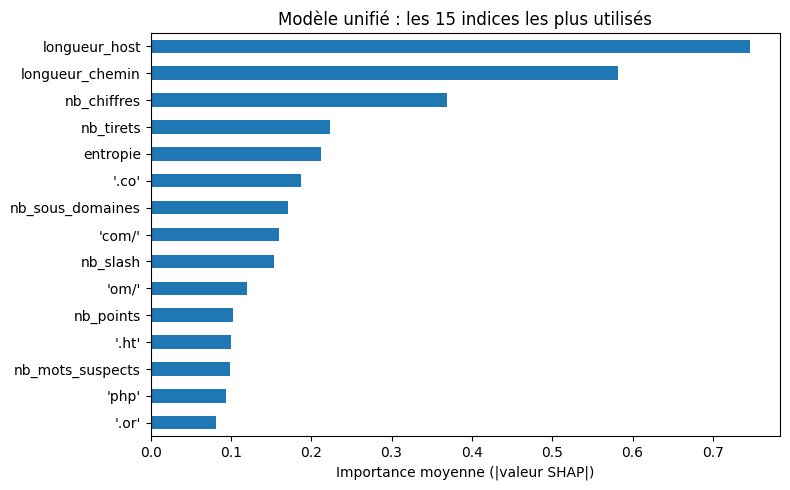


Sauvegardé. Versions : sklearn 1.6.1 | xgboost 3.4.1


In [17]:
import json, joblib, sklearn
import matplotlib.pyplot as plt

# 1. SHAP : les 15 indices les plus utilisés par le modèle (sur 2 000 liens de validation)
noms = FEATURES + [f"'{g}'" for g in tfidf.get_feature_names_out()]
contrib = modele.get_booster().predict(xgb.DMatrix(X_va[:2000]), pred_contribs=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(axis=0), index=noms).sort_values(ascending=False).head(15)
print(imp.round(3).to_string())
plt.figure(figsize=(8, 5))
imp[::-1].plot.barh()
plt.xlabel("Importance moyenne (|valeur SHAP|)")
plt.title("Modèle unifié : les 15 indices les plus utilisés")
plt.tight_layout()
plt.savefig(f"{MODELS}/shap_top15_unifie.png", dpi=150)
plt.show()

# 2. Sauvegarde (format natif XGBoost = portable Windows / Linux)
modele.save_model(f"{MODELS}/unifie_xgb.json")
joblib.dump(tfidf, f"{MODELS}/unifie_tfidf.joblib")
infos = {"modele": "XGBoost unifié (liens collés + liens des QR codes)",
         "features": FEATURES, "seuil_suspect": S_SUSPECT, "seuil_dangereux": S_DANGER,
         "normalisation": "sans schéma, sans www, domaine en minuscules, sans paramètres, sans / final",
         "donnees": "PhreshPhish 2025 + Quishing Dataset (liens décodés)",
         "sklearn": sklearn.__version__, "xgboost": xgb.__version__}
json.dump(infos, open(f"{MODELS}/unifie_infos.json", "w"), indent=2, ensure_ascii=False)
res_val.round(4).to_csv(f"{MODELS}/unifie_resultats_validation.csv")
res_test.round(4).to_csv(f"{MODELS}/unifie_resultats_test.csv")
print("\nSauvegardé. Versions : sklearn", sklearn.__version__, "| xgboost", xgb.__version__)